# Lesson 19: Sampled Current Voltammetry
We have seen how mass transfer affects the measured reaction rates (current) as a function of time. This lesson will explore the behavior further, showing how thermodynamics are factored in and expanding on the *mass transfer coefficient*.

Today's topics:
- Generalizing chronoamperometric behavior
- Voltammetric analysis
- Refining boundary conditions

**Reference:**
- Section 5.4 in *Electrochemical Methods: Fundamentals and Applications*, Allen J. Bard & Larry R. Faulkner.
---

## Configure Environment

In [1]:
import sys
if '../Resources' not in sys.path:
    sys.path.append('../Resources')     # so that echem.py can be found

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets

import echem                            # the shared toolkit for this course
from echem import R, T, F, f, WIDE      # constants and the two-panel figure size
echem.use_style()                       # course-wide graph formatting

# Experimental settings shared by every figure in this lesson
POTENTIAL = np.linspace(-0.3, 0.3, 201)     # V vs E0'
CONC_TOTAL = 1e-6                           # mol/cm3

# 1. Interactions Between Mass Transfer and Kinetics

Recalling that the total current measured for a given reaction is the sum of the anodic ( $i_a$ ) and cathodic ( $i_c$ ) portions, and that the sign direction of current flow between these portions is reversed, we can write:

 $\large i = i_a - i_c $ 

As established in [Lesson 11](L11-Kinetics-I-ButlerVolmer.ipynb), this course takes **anodic currents as positive**. You will meet the opposite convention throughout the literature, where the same quantity is written $i = i_c - i_a$ ; the chemistry is identical and only the sign of $i$ changes.

The **current-overpotential equation**, which will continually arise in our discussions, provides an explicit description for $i_a$ and $i_c$ :

$
\large i = i_0 \left[ \frac{C_R(0,t)}{C_R^*} e^{(1-\alpha) F \eta / R T} - \frac{C_O(0,t)}{C_O^*} e^{-\alpha F \eta / R T} \right]
$

<div class="alert alert-block alert-danger">
<b>Memory Check:</b> How are kinetics, thermodynamics and mass transfer embodied in the current-overpotential equation?
</div>

[Lesson 14](L14-Mass-Transfer-Limitations.ipynb) described how mass transfer is expected affect current flow in an electrochemical reaction, where a diffusion layer grows with time unless actions are taken to prevent it. If the rate of an electrochemical reaction is limited by mass-transfer, then one can expect to see:

$
\large i_{lim,a} = nFAm_RC_R^*
$

and

$
\large i_{lim,c} = -nFAm_OC_O^*
$

Further details regarding the current-overpotential equation can be explored by remembering that the mass-transfer limited currents can be restructured as described in [Lesson 14](L14-Mass-Transfer-Limitations.ipynb) such that:

$
\large \frac{C_j(0,t)}{C_j^*} = 1-\frac{i}{i_{lim,j}}
$

Therefore, with anodic currents defined as positive:

$
\large i = i_0 \left[ \left( 1-\frac{i}{i_{lim,a}}\right)e^{(1-\alpha) F \eta/RT} - \left(1-\frac{i}{i_{lim,c}}\right) e^{-\alpha F \eta/RT} \right]
$

The $i/i_{lim,j}$ terms allow the behavior to be represented in a mass transfer normalized fashion. Consider the figure below. In which regions is the current flow limited by mass transfer? By kinetics?

In [2]:
overpotential = np.linspace(-1.2, 1.2, 100)

@interact(alphas=widgets.Text(value='0.3, 0.5, 0.7', description=r'$\alpha$, csv'),
          log_i0_over_ilim=widgets.FloatText(value=-3, step=1,
                                             description=r'$log(i_0/i_{lim})$'))
def plot_current_overpotential(alphas, log_i0_over_ilim):
    '''The full current-overpotential equation: kinetics AND transport at once.'''
    try:
        alphas = echem.parse_numbers(alphas, name='alpha')
    except ValueError as problem:
        print(problem)
        return
    i_lim_over_i0 = 1.0/np.power(10.0, log_i0_over_ilim)

    fig = plt.figure()
    ax = plt.subplot()
    ax.set_xlabel(r'$\eta$ /V')
    ax.set_ylabel(r'$i / i_{lim}$  (anodic positive)')
    for alpha in alphas:
        ax.plot(overpotential,
                echem.current_overpotential(overpotential, i_lim_over_i0, alpha),
                label=rf'$\alpha$ = {alpha}')
    ax.legend(fontsize=6, loc=4)

interactive(children=(Text(value='0.3, 0.5, 0.7', description='$\\alpha$, csv'), FloatText(value=-3.0, descrip…

<div class="alert alert-block alert-danger">
<b>Convention Check:</b> What are the conventions for the mathematical sign of current? Voltage?
</div>

The mass transfer coefficient, $m_j$ , is **dependent on time**, the **modes of mass transport** that are active, and on the **geometry of diffusion**. [Lesson 16](L16-Chronoamperometry.ipynb) explored how this term can be quantified following *assumptions* regarding characteristics of the system. A key outcome of this approach is that a mathematical description of $m_j$ can be approximated such that the value of $i_{lim,j}(t)$ can be predicted.

The **Cottrell equation** was established as the defining equation for mass-transfer limited currents at macrodisk electrodes. Macrodisk electrodes are those in which diffusion occurs only via a linear geometry:

$
\large i_d(t) = \frac{nFA\sqrt{D_j}C_j^*}{\sqrt{\pi t}}
$

In this situation, it can be explicitly defined that $i_d$ **is** $i_{lim,j}$ with:

$
\large m_j = \sqrt{\frac{D_j}{\pi t}}
$

The mathematics for ultramicroelectrodes must consider the addition of radial diffusion as well as linear diffusion, which yielded:

$
\large i_{ss} = 4nFD_jC_j^*r_0
$

Where $i_{ss}$ **is** $i_{lim,j}$ with:

$
\large m_j = \frac{4D_j}{\pi r_0}
$

These two examples show us that the time-dependence of mass transfer is predictable, given knowledge of the system. This allows us to make predictions as we do above...but this is done with knowledge of numerous parameters, including:
- $\alpha$ 
- $E^{0'}$ 
- $i_0$ 
- $C_O$ and $C_R$ 

What if we don't know one of these values? Or all of these parameters? Electrochemistry is often applied to study unknowns, or changes in behavior upon modification of the system. How does one analyze data without any of the above information?

# 2. Sampled Current Voltammetry

Unknown systems can be effectively studied because we know, in general, how a system will respond to a perturbation. The behavior following systematic perturbations of a system can be monitored and the results compared to theoretical predictions. [Lesson 16](L16-Chronoamperometry.ipynb) introduced the potential step experiment. Here, **sampled current voltammetry** will build upon those experiments.

**Sampled current voltammetry** can be broken into two concepts: 
- **Voltammetry** is the measuring of *current* following variation of *voltage*
- **sampled** reflects the concept of performing measurements at discrete intervals, each performed with a discrete potential step

#### Pulse Voltammetry Waveform:

Sampled current voltammetry relies upon a series of **voltage pulses**. The voltage waveform is described by:
- $\large E_i$ : Initial potential. A voltage that is typically chosen to be $E_{OC}$ , or some other voltage where no Faradaic charge is passed. 
- $\large \Delta E$ : Magnitude of voltage pulse.
- $\large t_1$ : Period for which the voltage is pulsed.
- $\large t_2$ : Period for which the electrode is allowed to rest between voltage pulses. **Must be large enough to re-establish initial equilibrium.**

In [3]:
@interact(e_i=widgets.FloatText(value=0.0, step=0.01, description=r'$E$ vs. $E_{OC}$'),
          e_pulse=widgets.FloatText(value=0.01, step=0.01, description=r'$\Delta E$'),
          t1=widgets.FloatText(value=0.1, step=0.1, description=r'$t_1$'),
          t2=widgets.FloatText(value=0.1, step=0.1, description=r'$t_2$'))
def plot_pulse_waveform(e_i, e_pulse, t1, t2):
    '''The sampled current waveform: pulses of growing amplitude, each followed by a rest.'''
    if t1 <= 0 or t2 <= 0:
        print('Both times must be greater than zero.')
        return
    t, e = echem.pulse_waveform(e_initial=e_i, e_pulse=e_pulse,
                                t_rest=t2, t_pulse=t1, steps=3)

    fig = plt.figure()
    ax = plt.subplot()
    ax.set_xlabel('t /s')
    ax.set_ylabel(r'E / V vs. $E_{OC}$')

    ax.annotate('', fontsize=6, xy=(t2, e_i + e_pulse*0.5), xycoords='data',
                xytext=(t1 + t2, e_i + e_pulse*0.5), textcoords='data',
                arrowprops=dict(arrowstyle='<->', color='black'))
    ax.annotate(r'$t_1$', (t1/2 + t2, e_i + e_pulse*0.6), fontsize=6)

    ax.annotate('', fontsize=6, xy=(t1 + t2, e_i + e_pulse*0.5), xycoords='data',
                xytext=(t1 + 2*t2, e_i + e_pulse*0.5), textcoords='data',
                arrowprops=dict(arrowstyle='<->', color='black'))
    ax.annotate(r'$t_2$', (t1 + 1.5*t2, e_i + e_pulse*0.6), fontsize=6)

    ax.annotate('', fontsize=6, xy=(t2/2, e_i), xycoords='data',
                xytext=(t2/2, e_i + e_pulse), textcoords='data',
                arrowprops=dict(arrowstyle='<->', color='black'))
    ax.annotate(r'$\Delta E$', (t2/8, e_i + e_pulse/2), fontsize=6)

    ax.annotate('', fontsize=6, xy=(2*t2 + 1.5*t1, e_i), xycoords='data',
                xytext=(2*t2 + 1.5*t1, e_i + 2*e_pulse), textcoords='data',
                arrowprops=dict(arrowstyle='<->', color='black'))
    ax.annotate(r'$2\Delta E$', (2*t2 + 1.6*t1, e_i + e_pulse), fontsize=6)
    ax.annotate(r'$E_i$', (0, e_i), fontsize=6)

    ax.plot(t, e, 'blue')

interactive(children=(FloatText(value=0.0, description='$E$ vs. $E_{OC}$', step=0.01), FloatText(value=0.01, d…

#### The Sampled Current Voltammetry Experiment
Let us first consider our standard generic reaction:

$
\large O + e^- \rightleftharpoons R
$

Where all initial material is present as $O$ , so stepping to increasingly negative potentials drives a reduction and the measured currents are cathodic. This matches the boundary conditions used in the derivation below, and Bard & Faulkner's treatment of the same experiment. Sampled current voltammetry is performed by performing a series of potential steps of increasing magnitude and measuring the resultant current. Under mass transfer limited conditions this means that the **Cottrell equation** is continually applied.

To facilitate visualization we can define a *python function* that takes the necessary information to calculate the mass transfer limited current using the Cottrell equation. The function can then be used to plot the expected current for any selected voltage:

In [4]:
# The Cottrell equation and the Nernstian wave shape both live in echem.py:
#
#     echem.cottrell(t, conc, diff_coeff, area, n)          the current ceiling
#     echem.nernst_fraction_reduced(E, e_formal, n)         the fraction demanded
#     echem.sampled_current(E, t, conc_total, ..., starting_species='O')
#
# Sign convention: anodic (oxidation) currents are positive, so the cathodic
# currents in this lesson are NEGATIVE.  The figures below plot -i, so that
# the familiar Cottrell decay still falls towards zero on the page.
help(echem.sampled_current)

Help on function sampled_current in module echem:

sampled_current(potential, t, conc_total, diff_coeff=1e-05, area=1.0, n=1, e_formal=0.0, starting_species='R')
    Current measured at time ``t`` after a step to ``potential``.
    
    The Cottrell current tells you the biggest current the solution can supply.
    The Nernst equation tells you what fraction of that the applied potential
    actually demands.  Multiply them::
    
        i(E, t) = fraction_oxidized(E) * i_d(t)
    
    This is the calculation behind sampled current voltammetry (Lesson 20),
    normal pulse voltammetry (Lesson 23) and the shape of a linear sweep
    (Lesson 25): the wave has the shape of the Nernst equation and the height
    of the Cottrell equation.
    
    ``starting_species`` selects which experiment you are describing:
    
        'R' (default)  solution starts entirely as R.  Sweeping positive drives
                       an oxidation; the current is ANODIC (positive) and the
                 

<div class="alert alert-block alert-info">
<b>Activity:</b> Use the cell below to explore the behavior of the Cottrell equation. Note observations in the markdown cell underneath.
</div>


In [9]:
@interact(potentials=widgets.Text(value='0, -0.5', description=r'$E$ (csv)'))
def plot_cottrell(potentials):
    '''Chronoamperometry at two potentials.  Same shape; different height.'''
    try:
        potentials = echem.parse_numbers(potentials, name='potential')
    except ValueError as problem:
        print(problem)
        return

    fig = plt.figure(figsize=WIDE)
    ax1 = plt.subplot(121)
    ax2 = plt.subplot(122)
    t = np.linspace(0.005, 2, 500)

    for e in potentials:
        current = echem.sampled_current(e, t, CONC_TOTAL, starting_species='O')
        ax1.plot(t, -current*1000, label=f'{e} V')
        ax2.plot(t, -current*1000, label=f'{e} V')
    ax1.annotate(r'$-i \propto \frac{\sqrt{D_i}}{\sqrt{t}}$', (0.25, 0.5), fontsize=8)
    ax1.legend(loc=(0.7, 0.7), fontsize=6)
    for ax in [ax1, ax2]:
        ax.set_xlabel(r'$t$ /s')
        ax.set_ylabel(r'$-i$ /mA')

    ax2.set_xlim(0, 0.5)
    ax2.axvline(0.2, linestyle=':', color='gray')
    ax2.annotate(r'$t=\tau$', (0.18, 1.0), rotation=90, fontsize=8)
    ax2.annotate(r'$-i(\tau)$', (0.21, 0.5), fontsize=8)

interactive(children=(Text(value='0, -0.5', description='$E$ (csv)'), Output()), _dom_classes=('widget-interac…

#### Observations
- ...
- ...

#### Establishing a Model

The mathematics can be worked out exactly as before: define a series of boundary conditions that enable the partial differential equations to be solved. In this situation, however, the boundary condition at the electrode interface must be reconsidered. We will also further generalize by including the concentration of both species involved in the redox reaction (though we will remain with 100% O in solution). At a macrodisk electrode, the **diffusion equations** would be based on pure linear diffusion:

 $\large \frac{\delta C_O(x,t)}{\delta t} = D_O \frac{\delta^2 C_O(x,t)}{\delta x^2}$ 

 $\large \frac{\delta C_R(x,t)}{\delta t} = D_R \frac{\delta^2 C_R(x,t)}{\delta x^2}$ 

The **initial conditions**:

 $\large C_O(x,0)=C_O^*$ 

 $\large C_R(x,0)=0$ 

We will make the **semi-infinite diffusion** approximation:

 $\large \lim_{x \to \infty} C_O(x,t) = C_O^*$ 

 $\large \lim_{x \to \infty} C_R(x,t) = 0$ 

<div class="alert alert-block alert-info">
<b>Activity:</b> Consider the markdown cell below. What is the physical meaning of the first mathematical condition? What should serve as the condition at the electrode boundary?
</div>

We now have two species under consideration. **A new relationship** between these can be defined:

$ 
\large D_O\left(\frac{\delta C_O(x,t)}{\delta x}\right)_{x=0} + D_R \left(\frac{\delta C_R(x,t)}{\delta x} \right)_{x=0} = 0
$

At the **electrode boundary**, the concentration of species is represented by:

$
\large ??
$

---

A series of **Laplace transforms** using these conditions yields the current ( $i$ ) at an arbitrary time ( $t$ ) after a voltage step. For the **cathodic step** defined above, we can select a specific time (labeled $\tau$ ) and see that:

$
\large i(E, \tau) = \frac{nFA\sqrt{D_O}C_O^*}{\sqrt{\pi \tau}(1 + \xi \theta)}
$

Where the **dimensionless mass transfer term** ( $\xi$ ) is:

$
\large \xi = \sqrt{\frac{D_O}{D_R}}
$

And a dimensionless term describing the **thermodynamic equilibrium term** ( $\theta$ ) is derived from the Nernst equation:

$
\large \theta = \frac{C_O}{C_R} = e^{nF(E-E^{0'})/RT}
$

The **concentration at the electrode surface** during the potential step can be defined as (see [Lesson 14](L14-Mass-Transfer-Limitations.ipynb)):

$
\large C_O(0,\tau) = C_O^*\left[1-\frac{i(\tau)}{i_d(\tau)}\right]
$

Substitution yields:

$
\large C_R(0, \tau) = \xi C_O^*\left[\frac{i(\tau)}{i_d(\tau)}\right]
$

The **concentration profiles** can be calculated similar to how it was done in [Lesson 14](L14-Mass-Transfer-Limitations.ipynb), and is described in detail on page 179 in Bard & Faulkner's textbook.

#### Comparison to the Cottrell Equation

The $i(E, t)$ equation describes the generalized behavior for a potential step at any arbitrary voltage and time. A side-by-side comparison of this equation with the Cottrell equation shows their relationship to one another:

$
\large i_d(t) = \frac{nFA\sqrt{D_j}C_j^*}{\sqrt{\pi t}}
$

$
\large i(E, \tau) = \frac{nFA\sqrt{D_O}C_O^*}{\sqrt{\pi \tau}(1 + \xi \theta)}
$

It is clear that the generalized equation can be rewritten as:

$
\large i(E, \tau) = \frac{i_d(\tau)}{1 + \xi \theta}
$

The dimensionless mass transfer term is a constant, but the $\theta$ term depends on the applied voltage. This term becomes zero when a large cathodic overpotential is applied. The Cottrell equation is therefore the limit of the generalized behavior, taken at large overpotential.

# 3. Application to Macrodisk Electrodes

The final equation from the previous section can be rearranged to:

$
\large \theta = \frac{i_d(\tau) - i(\tau)}{\xi \cdot i(\tau)}
$

Following the definition of $\theta$ from above, we can expand the equation to:

$
\large E = E^{0'} + \frac{RT}{nF}ln(\xi^{-1}) + \frac{RT}{nF}ln\left( \frac{i_d(\tau) - i(\tau)}{i(\tau)}\right)
$

Which is:

$
\large E = E^{0'} + \frac{RT}{nF}ln\left(\sqrt{\frac{D_R}{D_O}}\right) + \frac{RT}{nF}ln\left( \frac{i_d(\tau) - i(\tau)}{i(\tau)}\right)
$

With this equations, the behavior for a potential step becomes directly applicable to experimental information: it is no longer an abstract concept that requires known parameters.

<div class="alert alert-block alert-info">
<b>Activity:</b> Mathematically describe the expected $E_{1/2}$ value for a sampled current voltammetry experiment.
</div>

$
\large E_{1/2} = ??
$

---

Based on the equation that is generated, it should be apparent that the experimental output is expected to exhibit a systematic shape: the shape is that of the **Nernst equation**

This brings us to an important understanding: **under mass-transfer limited conditions we observe thermodynamic control.** Electron transfer kinetics have absolutely no impact under these limiting conditions. This is confirmed below.

In [6]:
# Sampling the chronoamperograms at a fixed time turns a family of i-t curves
# into a single i-E curve.  The calculation is written as a plain function so
# that the cells below can reuse it without depending on the slider.
TIME = np.linspace(0.005, 2, 500)


def sample_at(tau):
    '''Return the current sampled at time tau, for every potential in POTENTIAL.'''
    return echem.sampled_current(POTENTIAL, tau, CONC_TOTAL, starting_species='O')


# The two sampling times used in the figures below
TAU_1 = 0.2     # s
TAU_2 = 0.3     # s
sampled_current_1 = sample_at(TAU_1)
sampled_current_2 = sample_at(TAU_2)


@interact(tau_1=widgets.FloatText(step=0.02, value=TAU_1, description=r'$\tau_1$'),
          tau_2=widgets.FloatText(step=0.02, value=TAU_2, description=r'$\tau_2$'))
def plot_sampled_current(tau_1, tau_2):
    '''Left: the raw chronoamperograms.  Right: the wave they build.'''
    if tau_1 <= 0 or tau_2 <= 0 or max(tau_1, tau_2) > TIME.max():
        print(f'Both sampling times must be between 0 and {TIME.max()} s.')
        return

    fig = plt.figure(figsize=WIDE)
    ax1 = plt.subplot(121)
    ax1.set_title('Chronoamperometry')
    ax2 = plt.subplot(122)
    ax2.set_title('Sampled Current Voltammetry')

    for potential in POTENTIAL:
        ax1.plot(TIME, -echem.sampled_current(potential, TIME, CONC_TOTAL,
                                              starting_species='O')*1000)
    ax1.set_xlabel('time /s')
    ax1.set_ylabel(r'$-i$ /mA')
    ax1.set_xlim(0, 0.5)
    for tau, label, colour in [(tau_1, r'$\tau_1$', 'gray'), (tau_2, r'$\tau_2$', 'lightgray')]:
        ax1.axvline(tau, linestyle=':', color=colour)
        ax1.annotate(label, (tau + 0.01, 1.2), fontsize=6)
    ax1.annotate(r'-E', (0.05, 1.0), fontsize=6)

    ax2.scatter(POTENTIAL, -1000*sample_at(tau_1), label=rf'$\tau$ = {tau_1} s')
    ax2.scatter(POTENTIAL, -1000*sample_at(tau_2), label=rf'$\tau$ = {tau_2} s')
    ax2.set_xlim(-0.2, 0.2)
    ax2.set_xlabel(r"E /V vs E$^{0'}$")
    ax2.set_ylabel(r'$-i$ /mA')
    ax2.legend(fontsize=6, loc=2)

interactive(children=(FloatText(value=0.2, description='$\\tau_1$', step=0.02), FloatText(value=0.3, descripti…

E_1/2  measured at +0.000 V
|E_3/4 - E_1/4| = 54.0 mV (56.4 mV expected for a reversible one-electron couple)


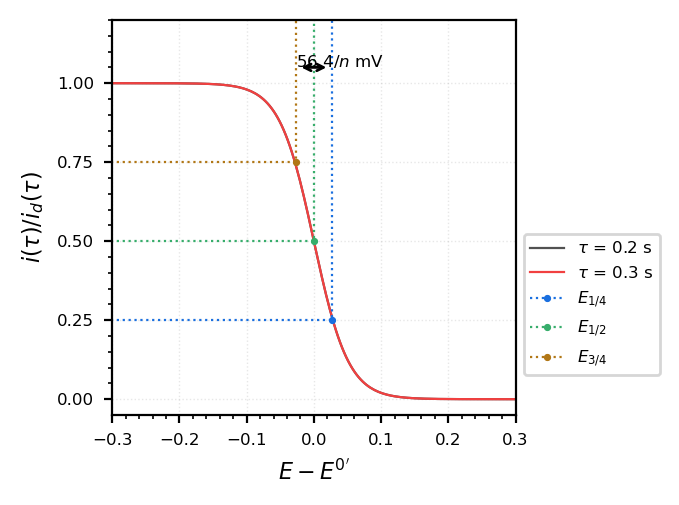

In [7]:
# The wave is the Nernst equation in disguise.  Normalising by the plateau makes
# that obvious, and lets us read off the three landmark potentials.
# These are CATHODIC currents, so they are negative and the plateau is the
# most negative value.  Normalising by it gives a positive 0-1 fraction that
# FALLS with E, which is the mirror image of the anodic wave in Lesson 23.
i_d_1 = sampled_current_1.min()
i_d_2 = sampled_current_2.min()

i_norm = sampled_current_1/i_d_1
i_norm_2 = sampled_current_2/i_d_2

idx_14 = echem.nearest_index(i_norm, 0.25)
idx_half = echem.nearest_index(i_norm, 0.50)
idx_34 = echem.nearest_index(i_norm, 0.75)

fig = plt.figure()
ax = plt.subplot()
ax.set_xlim(POTENTIAL.min(), POTENTIAL.max())
ax.set_ylim(-0.05, 1.2)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_xlabel(r"$E - E^{0'}$")
ax.set_ylabel(r'$i(\tau)/i_d(\tau)$')
ax.plot(POTENTIAL, i_norm, label=rf'$\tau$ = {TAU_1} s')
ax.plot(POTENTIAL, i_norm_2, label=rf'$\tau$ = {TAU_2} s')

# The three landmarks are located FROM THE DATA, not assumed
for idx, fraction, label in [(idx_14, 0.25, r'$E_{1/4}$'),
                             (idx_half, 0.50, r'$E_{1/2}$'),
                             (idx_34, 0.75, r'$E_{3/4}$')]:
    ax.plot([-1, POTENTIAL[idx], POTENTIAL[idx]], [fraction, fraction, 2],
            'o', linestyle=':', label=label)

ax.annotate(r'56.4/$n$ mV', (POTENTIAL[idx_34], 1.05), fontsize=6)
ax.annotate('', fontsize=6,
            xy=(POTENTIAL[idx_14], 1.05), xycoords='data',
            xytext=(POTENTIAL[idx_34], 1.05), textcoords='data',
            arrowprops=dict(arrowstyle='<->', color='black'))

ax.legend(fontsize=6, loc=(1.02, 0.1))
fig.savefig('../Workspace/sampledcurrent-markup.png')

print(f'E_1/2  measured at {POTENTIAL[idx_half]:+.3f} V')
print(f'|E_3/4 - E_1/4| = {abs(POTENTIAL[idx_34] - POTENTIAL[idx_14])*1000:.1f} mV '
      f'(56.4 mV expected for a reversible one-electron couple)')

#### "Nernstian" Reversibility Checks

The concept of electrochemical reversibility was broadly introduced in [Lesson 10](L10-Thermodynamics-II.ipynb). We are now equipped to see it in action: **A system is considered electrochemically reversible if the observed behavior can be described by the Nernst equation**: Electron transfer kinetics can have no impact on the results.

In sampled current voltammetry, we learn to navigate mass transfer limitations and extract this thermodynamic behavior. Because the equation that describes the curve is a reflection of the Nernst equation, we can establish a mathematical check to prove the electrochemical reversibility. 
- A plot of E vs. $log((i_d(\tau) - i(\tau))/i(\tau))$ should yield a straight line with a predictable slope

<div class="alert alert-block alert-info">
<b>Question:</b> What is the slope of the diagram below? Why?
</div>

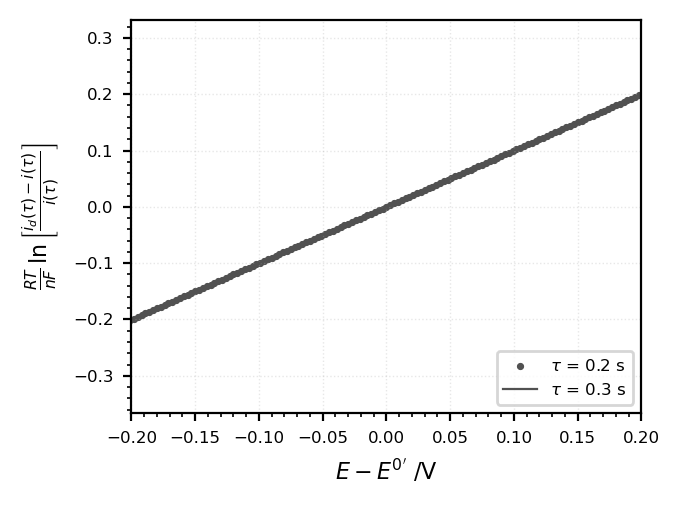

In [8]:
# The reversibility test: plot (RT/nF) ln[(i_d - i)/i] against E.
# A Nernstian system gives a straight line of slope 1 passing through E0'.
# The first two points are dropped because i approaches i_d there and the
# logarithm blows up.
check_1 = echem.THERMAL_VOLTAGE*np.log((i_d_1 - sampled_current_1[2:])/sampled_current_1[2:])
check_2 = echem.THERMAL_VOLTAGE*np.log((i_d_2 - sampled_current_2[2:])/sampled_current_2[2:])

fig = plt.figure()
ax = plt.subplot()
ax.scatter(POTENTIAL[2:], check_1, label=rf'$\tau$ = {TAU_1} s')
ax.plot(POTENTIAL[2:], check_2, label=rf'$\tau$ = {TAU_2} s')
ax.set_xlim(-0.2, 0.2)
ax.set_xlabel(r"$E - E^{0'}$ /V")
ax.set_ylabel(r'$\frac{RT}{nF} \, \ln \left[ \frac{i_d(\tau) - i(\tau)}{i(\tau)} \right]$')
ax.legend(fontsize=6, loc=4)

# 4. Application to Ultramicrodisk Electrodes

The same approach can be taken for the situation where radial diffusion contributes to mass flux. The mathematics is handled in Bard & Faulkner's textbook. The equations vary based on the time domain (Note that the specific equation depends on the geometry of the ultramicro electrode; these values are for a disk electrode):

#### Short time domain ( $\delta_0 << r_0$ ):

$
\large i(E, \tau) = \frac{nFA\sqrt{D_O}C_O^*}{\sqrt{\pi \tau}(1 + \xi \theta)}
$

#### Long time domain ( $\delta_0 >> r_0$ ):

$
\large i = \frac{4nFAD_OC_O^*}{\pi (1 + \xi^2 \theta)r_0}
$

Recall from [Lesson 16](L16-Chronoamperometry.ipynb) that a UME disk yielded a **steady state current** at long time frames, defined by:

$
\large i_{ss} = \frac{4nFAD_OC_O^*}{\pi r_0}
$

It is again obvious that this past equation is the simplification of the generalized equation. For the ultramicrodisk electrode we can write:

$
\large i = \frac{i_d}{(1 + \xi^2 \theta)}
$

Similar to the case for the macrodisk electrode, the $\theta$ portion can be isolated and expanded to yield:

$
\large E = E^{0'} + 
\frac{RT}{nF}ln\left[\frac{D_R}{D_O}\right]+\frac{RT}{nF}ln\left[\frac{i_d - i}{i}\right]
$

<div class="alert alert-block alert-info">
<b>Question:</b> Why were $t$ and $\tau$ left out of the final few equations?
</div>

# 5. Electrochemically Reversible ("Nernstian") Systems

In the situation where an electrochemical reaction is fully reversible (Nernstian and chemically), the behavior can be generalized based on the mass transfer coefficient. The mass transfer coefficient itself is dictated by the geometry of **diffusion** to the electrode. The general descriptions will always be:

$
\large i_c = nFAm_O[C_O^* - C_O(x=0)]
$

$
\large i_a = nFAm_R[C_R(x=0) - C_R^*]
$

REMEMBER: the signs for both of these equations may change, depending on the convention you choose!

The mass transfer coefficients for many electrode geometries have been worked out. Some common shapes are given in the table below. A more comprehensive list is available in Table 5.3.1 in Bard & Faulkner's textbook.

| | Macrodisk | UME Band | UME Cylinder | UME Disk | UME Hemisphere |
|---|---|---|---|---|---|
| m_j = | $\large \sqrt{\frac{D_j}{\pi t}}$ | $\large \frac{2\pi D_j}{w \cdot ln\left(\frac{64D_j t}{w^2}\right)}$ | $\large \frac{2D_j}{r_0ln(\tau)}$ | $\large \frac{4D_j}{\pi r_0}$ | $\large \frac{D_j}{r_0}$ |